# 2.2 Child population density and childcare centres (weighted KDE)

Where do young children live, and do the centres sit where the children are? This notebook
converts Kenneth's `scripts/plot_child_centre_kde_map.py`: HDB block centroids weighted by the
number of children aged 0–6 are binned to a 100 m grid and smoothed with a Gaussian kernel
(sigma 800 m), giving a continuous demand surface; the 1,796 childcare centres are overlaid as
uniform point symbols. It is a descriptive map that motivates the Ripley's K test (2.3) and the
supply-per-child analysis (2.5, stage 3).

Original author: Kenneth. Converted 2026-11-10 with one agreed change: the block weight is the
project's `child_0_6` column (`docs/decisions.md` 2026-11-02, per-subzone share of ages 5–6) instead
of the script's flat `child_0_4 + 0.40 × child_5_9`.

**Inputs**
- `output/hdb_blocks.gpkg`, layer `hdb_points` (10,769 residential block centroids with `OBJECTID`, EPSG:3414; stage 1)
- `output/hdb_access_children.csv` (per-block children 0–4 / 5–9 and `child_0_6`; stage 1 `build_subzone_stats`)
- `output/childcare_centres_2026.gpkg`, layer `centres` (canonical 1,796 centres, Jessie)
- `data/MasterPlanSubZones_2019.geojson` (land mask and reference boundaries)

**Outputs**
- `figures/child_centre_kde_map.png` (report and deck)

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch
from scipy.ndimage import gaussian_filter

# Fixed figure palette (docs/notebook_style.md): categorical order blue, orange, aqua, yellow;
# sequential = single-hue Blues; text in dark grey, never in a series colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#333333", "#52514e", "#e6e5e1", "#ffffff"
plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.edgecolor": GRID, "figure.facecolor": SURF,
                     "savefig.facecolor": SURF, "font.size": 9})

GRID_RES = 100      # grid cell size in metres
BW_M = 800          # Gaussian smoothing bandwidth (sigma) in metres
MIN_FRAC = 0.002    # cells below this fraction of the peak are made transparent
CENTRE_SIZE, CENTRE_ALPHA = 7, 0.75
LAND_FILL, LAND_OUTLINE = "#e8e8e8", "#888888"

## 1. Load the blocks and attach the children 0–6 weight

Kenneth's script read the block polygons from `hdb_blocks_children_final.gpkg` and recomputed a
flat-40% weight. The project has since settled on `child_0_6` with a per-subzone share of ages 5–6
(`docs/decisions.md`, 2026-11-02), which lives in `output/hdb_access_children.csv` keyed by
`OBJECTID`. That gpkg has no `OBJECTID`, so the centroids are taken from `hdb_points` in
`hdb_blocks.gpkg` instead; its points are exactly the centroids of those polygons (checked, maximum
distance 0 m), so the surface is built from the same locations.

In [2]:
# 1. Block centroids with OBJECTID (EPSG:3414, metres).
blocks = pyogrio.read_dataframe(OUT / "hdb_blocks.gpkg", layer="hdb_points",
                                columns=["OBJECTID", "SUBZONE_N", "PLN_AREA_N"])
print(f"{len(blocks):,} residential block centroids, CRS {blocks.crs.to_epsg()}")

# 2. changed 2026-11-10: weight = child_0_6 from hdb_access_children.csv (child_0_4 + share_5_6 x
#    child_5_9, share per subzone), joined on OBJECTID, instead of recomputing 0.40 x child_5_9.
#    Reason: one demand band for the whole project (decisions.md 2026-11-02); the flat-40% column
#    is kept only as a robustness check elsewhere.
children = pd.read_csv(OUT / "hdb_access_children.csv",
                       usecols=["OBJECTID", "child_0_4", "child_5_9", "child_0_6", "child_0_6_flat40"])
blocks = blocks.merge(children, on="OBJECTID", how="left", validate="one_to_one")
print(f"blocks with a child count: {blocks['child_0_6'].notna().sum():,}")
print(f"children 0-6 (per-subzone share): {blocks['child_0_6'].sum():,.0f};  "
      f"flat 40% rule (Kenneth's script): {blocks['child_0_6_flat40'].sum():,.0f}")

# 3. Only blocks with children contribute to the surface (as in the script).
blocks = blocks[blocks["child_0_6"].fillna(0) > 0].copy()
print(f"{len(blocks):,} blocks with children 0-6 > 0 enter the KDE")
cx, cy, w = blocks.geometry.x.to_numpy(), blocks.geometry.y.to_numpy(), blocks["child_0_6"].to_numpy()

10,769 residential block centroids, CRS 3414
blocks with a child count: 10,769
children 0-6 (per-subzone share): 176,409;  flat 40% rule (Kenneth's script): 177,548
10,755 blocks with children 0-6 > 0 enter the KDE


## 2. Load the centres and the land mask

In [3]:
# 1. Canonical centre layer (all service models count as supply, decisions.md 2026-11-01).
centres = pyogrio.read_dataframe(OUT / "childcare_centres_2026.gpkg", layer="centres",
                                 columns=["centre_code", "service_model"])
print(f"{len(centres):,} centres, CRS {centres.crs.to_epsg()}")
print(centres["service_model"].value_counts().to_string())

# 2. Subzones give the land background, the reference boundaries and the clip mask for the raster.
subzones = gpd.read_file(DATA / "MasterPlanSubZones_2019.geojson").to_crs(epsg=3414)
sg_land = subzones.union_all()
print(f"{len(subzones)} subzones; land area {sg_land.area / 1e6:,.0f} km2")

1,796 centres, CRS 3414
service_model
CC        1467
KN         183
DS          84
EYC-DS      57
EYC          5


332 subzones; land area 785 km2


## 3. Build the weighted density surface

Weighted centroids are summed into 100 m cells, then convolved with a Gaussian kernel of sigma =
800 m (8 cells). The result is children per cell, smoothed; because the kernel integrates to one,
the surface sums to the national child count and the peak can be read as "children per 100 m cell
in the neighbourhood of the peak". Cells below 0.2% of the peak are made transparent so the sea
and the empty west stay white.

In [4]:
# 1. Grid extent padded by four sigmas so the kernel does not get clipped at the edges.
pad = int(BW_M * 4)
x_min, x_max = cx.min() - pad, cx.max() + pad
y_min, y_max = cy.min() - pad, cy.max() + pad
xi = np.arange(x_min, x_max, GRID_RES)
yi = np.arange(y_min, y_max, GRID_RES)
density = np.zeros((len(yi), len(xi)), dtype=np.float64)

# 2. Bin the weighted centroids (np.add.at accumulates several blocks falling in one cell).
ix_idx = ((cx - x_min) / GRID_RES).astype(int)
iy_idx = ((cy - y_min) / GRID_RES).astype(int)
valid = (ix_idx >= 0) & (ix_idx < len(xi)) & (iy_idx >= 0) & (iy_idx < len(yi))
np.add.at(density, (iy_idx[valid], ix_idx[valid]), w[valid])

# 3. Gaussian smoothing; sigma in cells.
sigma = BW_M / GRID_RES
density_smooth = gaussian_filter(density, sigma=sigma)
peak = density_smooth.max()
density_plot = np.where(density_smooth >= peak * MIN_FRAC, density_smooth, np.nan)
print(f"grid: {len(xi)} x {len(yi)} cells of {GRID_RES} m; sigma = {sigma:.0f} cells")
print(f"weight binned: {density.sum():,.0f} children; after smoothing: {density_smooth.sum():,.0f}")
print(f"peak density = {peak:.2f} children per cell (= {peak * 100:,.0f} per km2 smoothed)")

grid: 376 x 271 cells of 100 m; sigma = 8 cells
weight binned: 176,409 children; after smoothing: 176,409
peak density = 21.13 children per cell (= 2,113 per km2 smoothed)


In [5]:
# 1. Which neighbourhoods are the hotspots? Sample the smoothed surface at each block and take the
#    highest value per subzone (the surface is smoother than subzones, so this ranks the peaks).
blocks["density_at_block"] = density_smooth[iy_idx, ix_idx]
hotspots = (blocks.groupby(["SUBZONE_N", "PLN_AREA_N"])
            .agg(peak_density=("density_at_block", "max"), children_0_6=("child_0_6", "sum"))
            .sort_values("peak_density", ascending=False))
hotspots["peak_per_km2"] = hotspots["peak_density"] * 100
print("top 10 subzones by peak smoothed child density (children 0-6 per km2):")
print(hotspots.head(10).round(0).to_string())
print("\nplanning areas of the 20 highest-density subzones:")
print(hotspots.head(20).reset_index()["PLN_AREA_N"].value_counts().to_string())

top 10 subzones by peak smoothed child density (children 0-6 per km2):
                                  peak_density  children_0_6  peak_per_km2
SUBZONE_N            PLN_AREA_N                                           
TAMPINES NORTH       TAMPINES             21.0        6838.0        2113.0
TAMPINES EAST        TAMPINES             21.0        5092.0        2088.0
MATILDA              PUNGGOL              20.0        3565.0        2043.0
PUNGGOL FIELD        PUNGGOL              20.0        2087.0        2030.0
SENGKANG TOWN CENTRE SENGKANG             20.0        2985.0        2029.0
TAMPINES WEST        TAMPINES             20.0        5603.0        2028.0
RIVERVALE            SENGKANG             20.0        2927.0        2011.0
WATERWAY EAST        PUNGGOL              19.0        3879.0        1876.0
PUNGGOL TOWN CENTRE  PUNGGOL              19.0        1664.0        1856.0
BRICKWORKS           BUKIT BATOK          19.0        3741.0        1855.0

planning areas of the 20 hig

## 4. Map

Land in light grey, the smoothed child surface on the Blues ramp (clipped to the coastline so the
kernel does not bleed into the sea), subzone boundaries faint for orientation, and every centre as
an orange dot. The colour bar is left unlabelled on purpose: the surface is relative, the numbers
that matter are in the table above.

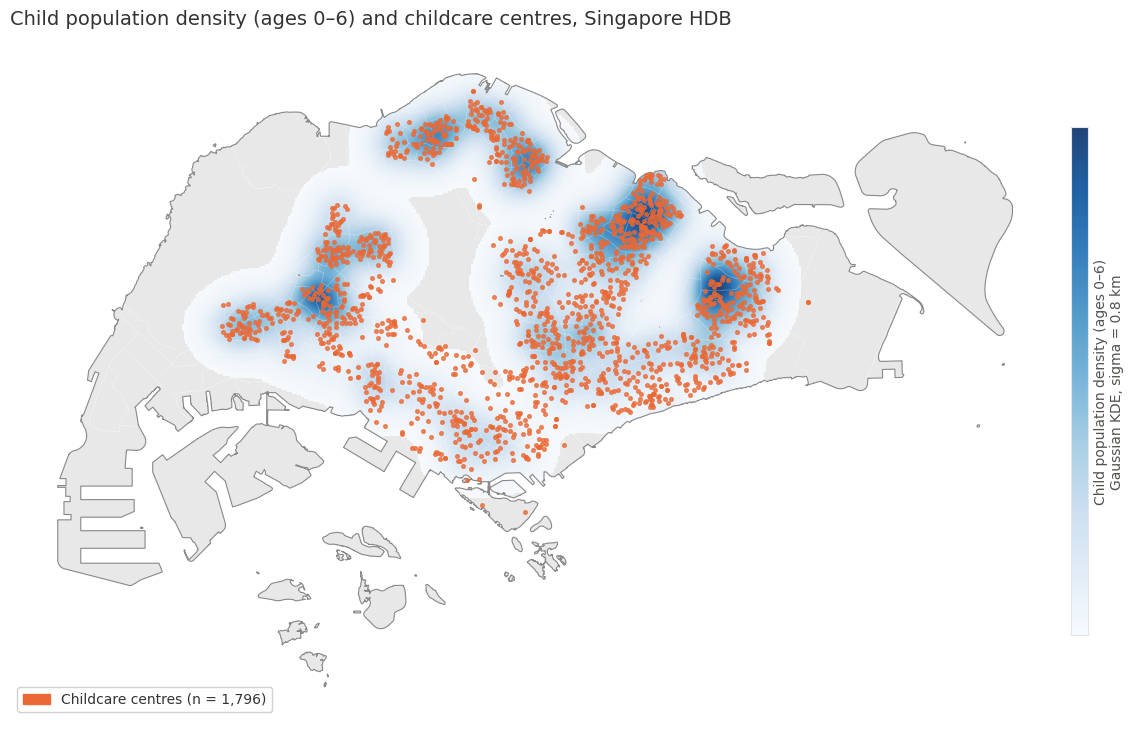

In [6]:
def shapely_to_mpl_path(geom):
    """Convert a shapely Polygon or MultiPolygon to a matplotlib Path for clip masking."""
    polys = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
    vertices, codes = [], []
    for poly in polys:
        for ring in [poly.exterior] + list(poly.interiors):
            coords = np.array(ring.coords)
            vertices.append(coords)
            codes.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(coords) - 2) + [MplPath.CLOSEPOLY])
    return MplPath(np.vstack(vertices), codes)

fig, ax = plt.subplots(figsize=(14, 12))
ax.set_aspect("equal")
ax.set_axis_off()

# 1. Land background, then the raster, clipped to the coastline.
subzones.plot(ax=ax, facecolor=LAND_FILL, edgecolor="none", zorder=0)
im = ax.imshow(density_plot, extent=[x_min, x_max, y_min, y_max], origin="lower",
               cmap="Blues", alpha=0.9, interpolation="bilinear", zorder=1)
im.set_clip_path(PathPatch(shapely_to_mpl_path(sg_land), transform=ax.transData))

# 2. Reference lines: faint subzone edges, firmer coastline.
subzones.plot(ax=ax, facecolor="none", edgecolor="white", linewidth=0.4, alpha=0.22, zorder=2)
subzones.dissolve().boundary.plot(ax=ax, color=LAND_OUTLINE, linewidth=0.8, zorder=3)

# 3. Centres as uniform symbols (changed 2026-11-10: orange on a Blues surface, repo palette;
#    the script used blue dots on YlOrRd).
centres.plot(ax=ax, color=ORANGE, markersize=CENTRE_SIZE, alpha=CENTRE_ALPHA, zorder=5, marker="o")

cbar = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.01, shrink=0.55, aspect=30)
cbar.set_label(f"Child population density (ages 0–6)\nGaussian KDE, sigma = {BW_M / 1000:.1f} km", fontsize=10)
cbar.set_ticks([])
ax.legend(handles=[mpatches.Patch(color=ORANGE, label=f"Childcare centres (n = {len(centres):,})")],
          loc="lower left", fontsize=10, frameon=True, framealpha=0.9)
ax.set_title("Child population density (ages 0–6) and childcare centres, Singapore HDB",
             fontsize=14, loc="left", pad=14)
fig.savefig(FIG / "child_centre_kde_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
print(f"wrote {(FIG / 'child_centre_kde_map.png').relative_to(ROOT)}  "
      f"({len(blocks):,} weighted blocks, {len(centres):,} centres)")

wrote figures/child_centre_kde_map.png  (10,755 weighted blocks, 1,796 centres)
